# Import

In [1]:
!pip install ultralytics -q
!pip install pillow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 108.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 118.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 90.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
!pip uninstall -y numpy scipy
!pip install numpy==1.26.4 scipy==1.11.4

Found existing installation: numpy 2.2.6
Uninstalling numpy-2.2.6:
  Successfully uninstalled numpy-2.2.6
Found existing installation: scipy 1.15.3
Uninstalling scipy-1.15.3:
  Successfully uninstalled scipy-1.15.3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 58.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
datasets 4.4.1 requires pyarrow>=21.0.0, but you have pyarrow 19.0.1 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
google-colab 1

In [3]:
import os
import random
import shutil
import numpy as np
import cv2
import pandas as pd
from PIL import Image, ImageEnhance
from pathlib import Path
import yaml
from tqdm import tqdm
from ultralytics import YOLO
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
from ultralytics.data import YOLODataset
from ultralytics.data.augment import Compose
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.utils.torch_utils import unwrap_model

# Data Path

In [ ]:
# Set seeds for reproducibility
random.seed(42)
np.random.seed(42)

dataset_path = '/kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg'
output_path = '/kaggle/working/lead_localization_yolov12'

os.makedirs(f'{output_path}/train/images', exist_ok=True)
os.makedirs(f'{output_path}/train/labels', exist_ok=True)
os.makedirs(f'{output_path}/val/images', exist_ok=True)
os.makedirs(f'{output_path}/val/labels', exist_ok=True)
os.makedirs(f'{output_path}/test/images', exist_ok=True)
os.makedirs(f'{output_path}/test/labels', exist_ok=True)

In [ ]:
def apply_ecg_augmentations(img):
    """Apply custom ECG augmentations to image"""
    
    # opencv uses 0-255
    if img.dtype != np.uint8:
        img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
    
    # Noise augmentation
    if random.random() < 0.5:
        noise = np.random.normal(0, 25, img.shape).astype(np.int16)
        noisy = cv2.add(img.astype(np.int16), noise)
        img = np.clip(noisy, 0, 255).astype(np.uint8)

    # Gaussian blur
    if random.random() < 0.3:
        k = random.choice([3, 5])
        img = cv2.GaussianBlur(img, (k, k), 0)

    # Random stains
    if random.random() < 0.3:
        for _ in range(random.randint(1, 3)):
            center = (random.randint(0, img.shape[1]), random.randint(0, img.shape[0]))
            radius = random.randint(3, 10)
            color = random.choice([(100, 100, 100), (200, 200, 200)])
            cv2.circle(img, center, radius, color, -1)

    # Brightness & contrast
    if random.random() < 0.7:
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
        pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    
    return img

In [7]:
# Define 13 classes: 12 leads + 1 rhythm
class_names = [
    'I', 'II', 'III', 'aVR', 'aVL', 'aVF',
        'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'II_rhythm'
]

data_yaml = {
    'path': dataset_path,
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': 13,
    'names': class_names
}

yaml_path = f'{output_path}/data.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print(f"Created yaml at {yaml_path}")

Created yaml at /kaggle/working/lead_localization_yolov12/data.yaml


In [ ]:
class ECGAugmentedDataset(YOLODataset):
    """Custom YOLO dataset with augmentations"""
    
    def load_image(self, i, rect_mode=False):
        im, f, fn = super().load_image(i, rect_mode) # inherit all YOLO default dataset (following ultralytics documentation)
        
        # Apply custom augmentations only during training
        if self.augment:
            if len(im.shape) == 3 and im.shape[2] == 3:
                im = apply_ecg_augmentations(im)
        
        return im, f, fn


class ECGDetectionTrainer(DetectionTrainer):
    def build_dataset(self, img_path, mode='train', batch=None):
        """Build dataset with custom augmentations"""
        gs = max(int(unwrap_model(self.model).stride.max() if self.model else 0), 32)
        
        # default from ultralytics documentation for making new YOLO Dataset
        return ECGAugmentedDataset(
            img_path=img_path,
            imgsz=self.args.imgsz,
            batch_size=batch,
            augment=mode == 'train',
            hyp=self.args,
            rect=False if mode == 'train' else self.args.rect,
            cache=self.args.cache or None,
            single_cls=self.args.single_cls or False,
            stride=int(gs),
            pad=0.0 if mode == 'train' else 0.5,
            prefix=colorstr(f'{mode}: '),
            task=self.args.task,
            classes=self.args.classes,
            data=self.data,
            fraction=self.args.fraction if mode == 'train' else 1.0,
        )

# Augmented Examples

Visualizing augmentations for: 7981.jpg


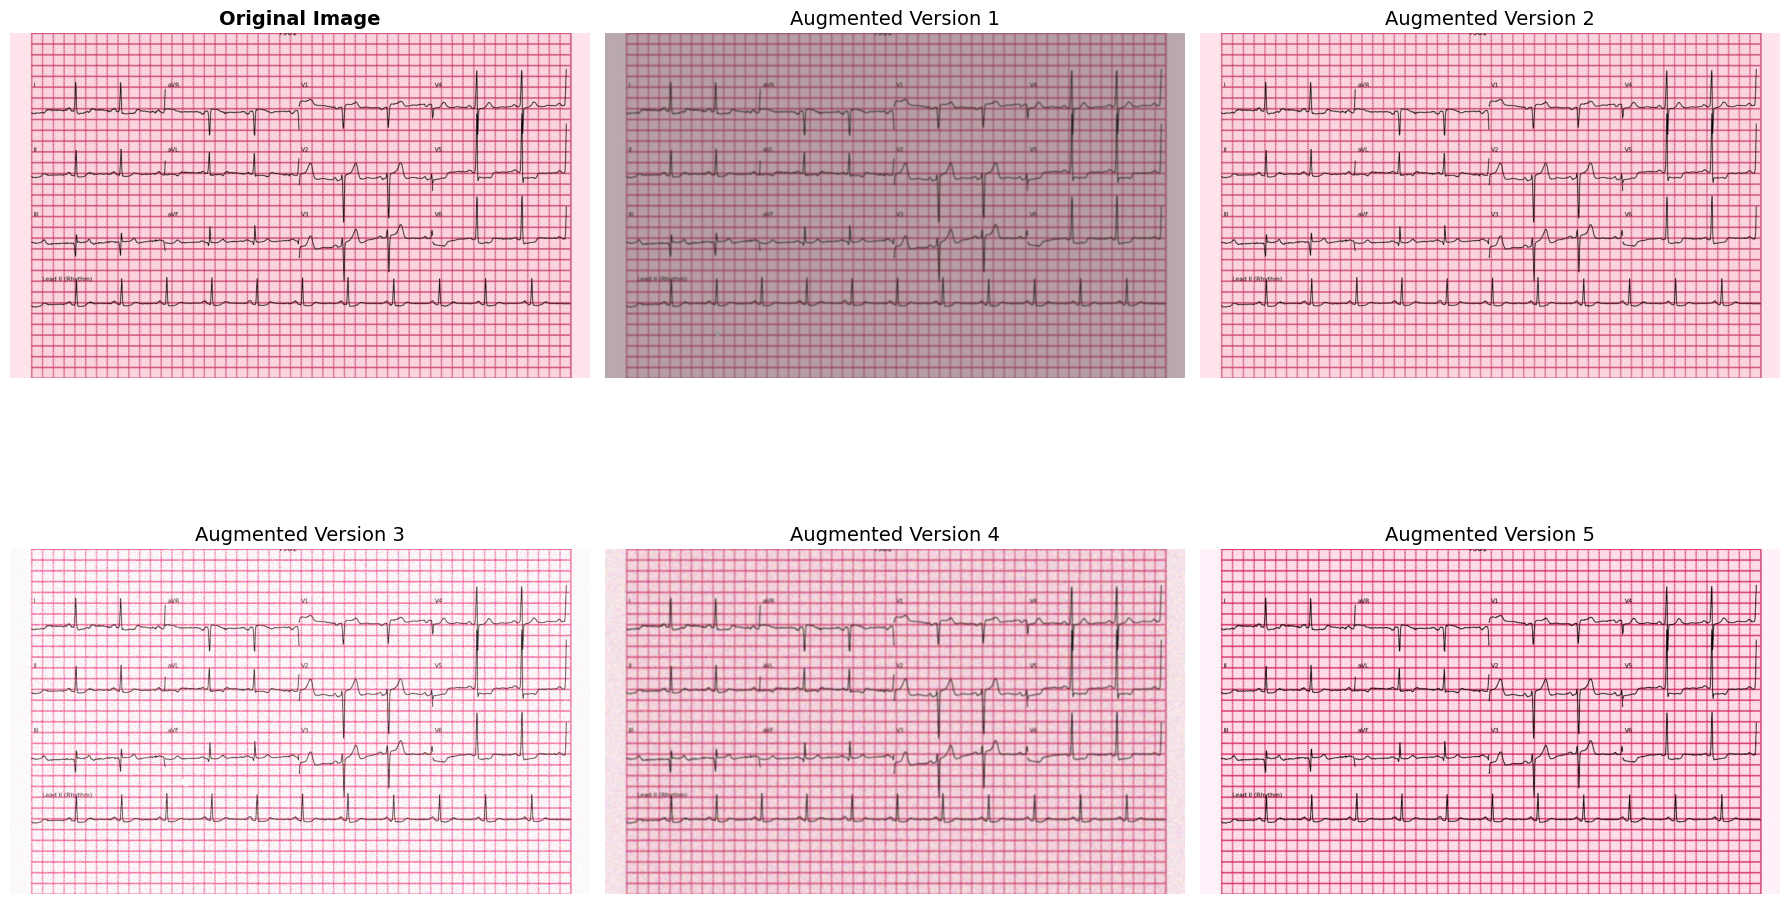

Augmentation visualization saved to: /kaggle/working/lead_localization_yolov12/augmentation_comparison.png


In [9]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from pathlib import Path

def visualize_augmentations(image_path, num_variations=5):
    # Read original image
    original = cv2.imread(image_path)
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    
    # Create figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    # Show original
    axes[0].imshow(original_rgb)
    axes[0].set_title('Original Image', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    # Generate and show augmented versions
    for i in range(1, min(6, num_variations + 1)):
        # Apply augmentations
        augmented = apply_ecg_augmentations(original.copy())
        augmented_rgb = cv2.cvtColor(augmented, cv2.COLOR_BGR2RGB)
        
        axes[i].imshow(augmented_rgb)
        axes[i].set_title(f'Augmented Version {i}', fontsize=14)
        axes[i].axis('off')
    
    # Hide unused subplots
    for i in range(num_variations + 1, 6):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.savefig(f'{output_path}/augmentation_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"Augmentation visualization saved to: {output_path}/augmentation_comparison.png")

train_img_dir = f'{dataset_path}/train/images'
if os.path.exists(train_img_dir):
    train_images = [f for f in os.listdir(train_img_dir) if f.endswith(('.jpg'))]
    if train_images:
        sample_image = os.path.join(train_img_dir, train_images[0])
        print(f"Visualizing augmentations for: {train_images[0]}")
        visualize_augmentations(sample_image, num_variations=5)

# Training

In [10]:
model = YOLO('yolo12n.pt')

model.trainer = ECGDetectionTrainer

results = model.train(
    data=yaml_path,
    epochs=30,
    imgsz=640,
    batch=16,
    save=True,
    project=output_path,
    name='ecg_lead_detection',
)

print("\nTraining completed")

Ultralytics 8.3.237 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/lead_localization_yolov12/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=ecg_lead_detection, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100,

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       3268      42484      0.998      0.998      0.995      0.989
                     I       3268       3268          1      0.999      0.995      0.994
                    II       3268       3268          1          1      0.995      0.994
                   III       3268       3268          1      0.999      0.995      0.992
                   aVR       3268       3268      0.999      0.999      0.995      0.994
                   aVL       3268       3268          1      0.998      0.995      0.989
                   aVF       3268       3268          1          1      0.995      0.989
                    V1       3268       3268          1      0.998      0.995      0.994
                    V2       3268       3268          1      0.997      0.995      0.994
                    V3       3268       3268      0.999      0.999      0.995      0.994
                    V4       3268       3268      0.999      0.999      0.995      0.994
                    V

In [11]:
best_model = YOLO(f'{output_path}/ecg_lead_detection/weights/best.pt')
val_results = best_model.val(
    data=yaml_path,
    imgsz=640,
    batch=16,
    save=True,
    save_txt=True
)
print(f"\nValidation Results:")
print(f"mAP50: {val_results.box.map50:.4f}")
print(f"mAP50-95: {val_results.box.map:.4f}")

Ultralytics 8.3.237 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,559,263 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 376.0±74.8 MB/s, size: 210.5 KB)
val: Scanning /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/val/labels... 3269 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 3269/3269 764.3it/s 4.3s
val: /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/val/images/16448.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     2.8033]
WARNING ⚠️ val: Cache directory /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 205/205 3.8it/s 53.4s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       3268      42484      0.998      0.998      0.995       0.99
                     I       3268       3268          1      0.999      0.995      0.994
                    II       3268       3268          1          1      0.995      0.994
                   III       3268       3268          1      0.999      0.995      0.992
                   aVR       3268       3268      0.999      0.999      0.995      0.994
                   aVL       3268       3268          1      0.998      0.995      0.989
                   aVF       3268       3268          1          1      0.995       0.99
                    V1       3268       3268          1      0.998      0.995      0.994
                    V2       3268       3268      0.999      0.997      0.995      0.994
                    V3       3268       3268      0.999      0.999      0.995      0.994
                    V4       3268       3268      0.999      0.999      0.995      0.994
                    V

In [12]:
test_results = best_model.val(
    data=yaml_path,
    imgsz=640,
    batch=16,
    split="test",
    save=True,
    save_txt=True
)
print("\nTest Results")
print(f"mAP50:     {test_results.box.map50:.4f}")
print(f"mAP50-95:  {test_results.box.map:.4f}")

Ultralytics 8.3.237 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.1±0.2 ms, read: 41.5±4.8 MB/s, size: 209.9 KB)
val: Scanning /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/test/labels... 3270 images, 1 backgrounds, 9 corrupt: 100% ━━━━━━━━━━━━ 3271/3271 238.5it/s 13.7s
val: /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/test/images/18767.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.2816      1.0429       1.022      1.2816]
val: /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/test/images/19528.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1601]
val: /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/test/images/19540.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     1.1909]
val: /kaggle/input/final-matplotlib-yolo-ecg/matplotlib_ecg/test/images/20014.jpg: ignoring corrupt image/label: non-nor

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       3262      42393      0.998      0.997      0.995      0.988
                     I       3261       3261      0.999      0.998      0.995      0.994
                    II       3261       3261          1      0.999      0.995      0.993
                   III       3261       3261      0.999      0.998      0.995      0.992
                   aVR       3261       3261      0.999      0.999      0.995      0.993
                   aVL       3261       3261      0.999      0.994      0.995      0.989
                   aVF       3261       3261          1          1      0.995      0.989
                    V1       3261       3261      0.999      0.996      0.995      0.994
                    V2       3261       3261      0.999      0.996      0.995      0.994
                    V3       3261       3261      0.998      0.998      0.995      0.994
                    V4       3261       3261      0.999      0.999      0.995      0.994
                    V